# 02 · Cropin's own forest layer and SAG, tested on the QC polygons

**Author:** Meera Mehta, MIT Analytics Lab × Cropin, Oct 2026
**Inputs:**
- `data/gee_exports/qc_cropin_layers.csv` and `qc_sag_timeseries.csv` (from `gee/03_cropin_layers_and_SAG_qc_export.js`);
- the notebook-01 inputs `qc_error_analysis_A.csv` and `qc_error_analysis_B_ndvi.csv`.

**Outputs:** `figures/02*.png`

On 2026-10-28 Cropin sent us their Earth Engine code (`gee/cropin/`, explained in
`gee/cropin/README.md`):
- the **forest-layer recipe** that very likely produced the QC alerts;
- **SAG**, a plantation detector based on how dark-green the canopy is in Oct–Jan, with a Bayesian update across years.

This notebook:
1. benchmarks Cropin's layer and the MapBiomas 10 m products on the QC set;
2. **validates SAG on labelled cases for the first time**;
3. tests whether "plantations are more uneven" was an artefact of measuring the surroundings;
4. adds the new signals to the notebook-01 model.

Statistics follow notebook 01 (AUC with bootstrap CIs, Mann–Whitney / Fisher, Holm correction,
spatially blocked CV with a nested threshold), using the same helpers in `src/qc_analysis.py`.
Everything is still **exploratory** on a biased sample (see notebook 01, section a).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
from qc_analysis import *

warnings.filterwarnings("ignore", category=FutureWarning)
# NumPy 2.x + Apple Accelerate: spurious matmul warnings in sklearn on macOS (predictions checked finite)
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
set_style()
SEED, N_BOOT, SEEDS = 0, 2000, range(20)
np.random.seed(SEED)
pd.set_option("display.precision", 3, "display.width", 140)

class MissingExportError(RuntimeError):
    pass

NEEDED = [DATA / "gee_exports/qc_cropin_layers.csv", DATA / "gee_exports/qc_sag_timeseries.csv"]
missing = [p.name for p in NEEDED if not p.exists()]
if missing:
    raise MissingExportError(
        f"Missing {missing}. Run gee/03_cropin_layers_and_SAG_qc_export.js in the Earth Engine Code Editor "
        "(project cropin-510901), click RUN on both tasks, download the CSVs from Google Drive/cropin_exports "
        "and put them in data/gee_exports/. Then rerun this notebook.")
print("inputs found:", [p.name for p in NEEDED])

inputs found: ['qc_cropin_layers.csv', 'qc_sag_timeseries.csv']


## Data

**Per-polygon table.** We merge Cropin's layer outputs with the notebook-01 features on `id`.
The Meta height columns come out of Earth Engine with generic names, so we rename them `meta_*`.
`meta_range` = p90 − p10 is a robust spread: the height gap between the tallest and shortest 10%
of 1 m pixels.

**SAG time series.** There is one row per polygon per Sentinel-2 image with at least one valid
dark pixel. Polygons in the overlap of two Sentinel-2 tiles appear twice on the same date.
- **For SAG averages**, we first average the two copies per date, so overlap polygons don't
  count double.
- **For the faithful rebuild of Cropin's posterior**, we keep both copies. Cropin's per-pixel
  code also ingests both images.

In [2]:
d = add_features(load_qc()).set_index("id")
cl = (pd.read_csv(NEEDED[0])
        .drop(columns=["system:index", ".geo"])
        .rename(columns={"mean": "meta_mean", "stdDev": "meta_sd", "p10": "meta_p10", "p90": "meta_p90", "count": "meta_npix"})
        .set_index("id"))
assert cl.index.is_unique and set(cl.index) == set(d.index)
assert (cl["qc_label"] == d.loc[cl.index, "qc_label"]).all()
cl["meta_range"] = cl["meta_p90"] - cl["meta_p10"]
d = d.join(cl.drop(columns="qc_label"))
y = d["y"]

sag = pd.read_csv(NEEDED[1], parse_dates=["date"]).rename(columns={"mean": "sag", "count": "npix"})
assert set(sag["id"]) == set(d.index)
sag["month"] = sag["date"].dt.month
dup = sag.duplicated(["id", "date"], keep=False)
print(f"SAG rows: {len(sag):,} | polygons: {sag.id.nunique()} | dates {sag.date.min().date()} to {sag.date.max().date()}")
print(f"rows that share (id, date) with another tile: {int(dup.sum()):,}")
sag_day = sag.groupby(["id", "date"], as_index=False).agg(sag=("sag", "mean"), npix=("npix", "sum"))
sag_day["month"] = sag_day["date"].dt.month
print(f"polygon-dates after averaging tile copies: {len(sag_day):,}")

SAG rows: 97,201 | polygons: 433 | dates 2019-01-01 to 2026-01-31
rows that share (id, date) with another tile: 22,355
polygon-dates after averaging tile copies: 85,683


## (i) Benchmark: Cropin's forest layer and MapBiomas 10 m on the QC cases

### What we expect
Every QC case is an alert raised by Cropin's forest layer. If the layer is exactly
`cropin_forest_layer.js` for 2020, then by construction every alert pixel had:
- an ensemble score ≥ 0.75;
- **not** MapBiomas 10 m plantation (class 9 in C2 or S2-beta);
- MapBiomas 10 m S2-beta forest (class 3);
- Meta height ≥ 4 m.

So MapBiomas 10 m should "miss" essentially *all* QC plantations. That would not be a failure of
MapBiomas on new data; it would be the selection rule.

### What we see
`cf_*` values are the **share of the polygon's 10 m pixels** passing each rule. We count a
polygon as passing when at least half its pixels pass.

In [3]:
comp = {"cf_score": "ensemble score (polygon mean) ≥ 0.75", "cf_hansen": "Hansen forest",
        "cf_jrc": "JRC GFC2020 forest", "cf_mb30c10_forest": "MapBiomas C10 30 m forest", "cf_tmf": "TMF forest",
        "cf_mb10_plant_any": "MapBiomas 10 m plantation (C2 or beta) - must be 0",
        "cf_mb10beta_forest": "MapBiomas 10 m beta forest", "cf_meta_ge4": "Meta height ≥ 4 m",
        "cf_forest_final": "FINAL Cropin forest flag"}
rows = []
for c, lab in comp.items():
    thr = 0.75 if c == "cf_score" else 0.5
    for k, sub in [("plantation", d[y == 1]), ("forest", d[y == 0])]:
        rows.append(dict(component=lab, group=k, pct_polygons_passing=100 * (sub[c] >= thr).mean(), mean_share=sub[c].mean()))
bench = pd.DataFrame(rows).pivot(index="component", columns="group", values="pct_polygons_passing").reindex(list(comp.values()))
display(bench.round(1).rename(columns={"plantation": "% of 310 plantations passing", "forest": "% of 123 forests passing"}))

group,% of 123 forests passing,% of 310 plantations passing
component,,
ensemble score (polygon mean) ≥ 0.75,98.4,98.7
Hansen forest,95.1,75.5
JRC GFC2020 forest,99.2,97.1
MapBiomas C10 30 m forest,100.0,100.0
TMF forest,100.0,100.0
MapBiomas 10 m plantation (C2 or beta) - must be 0,4.9,27.7
MapBiomas 10 m beta forest,95.1,78.7
Meta height ≥ 4 m,83.7,88.1
FINAL Cropin forest flag,76.4,54.5


**This does not match "by construction".**
- **Ensemble.** Nearly all polygons pass the ensemble score (and MapBiomas C10 30 m forest),
  which is consistent with the alerts coming from this layer.
- **Final flag.** Only about **55% of plantations and 76% of forests pass the final flag** at
  polygon level.
- **Which filters fail.** Mostly the **MapBiomas 10 m filters**. 28% of plantations are
  majority MapBiomas 10 m *plantation* in 2020, which the layer should have excluded, and 21% are
  not 10 m beta forest. Meta ≥ 4 m fails for only 12%.

Possible reasons (we can't tell which from here):
- Cropin's alerts used a different version, year or threshold of the layer.
- The alert was triggered by a few pixels inside the polygon, while we average over the whole polygon.
- The 10 m maps changed between the version Cropin ran and the public assets we queried. The
  10 m C2 and S2-beta are recent releases.

**Question for Cropin:** which layer version and year generated these alerts?

### MapBiomas class by product and year
Next we compare the three MapBiomas products Cropin's code uses, plus the C9 30 m we used in
notebook 01, year by year. For each product we count plantations called **plantation** (caught)
and **forest** (missed).

year,2016,2017,2018,2019,2020,2021,2022,2023,2024
product,,,,,,,,,
MapBiomas 10 m C2,10.0,9.0,10.0,21.0,34.0,46.0,77.0,76.0,–
MapBiomas 10 m S2-beta,28.0,41.0,46.0,48.0,53.0,64.0,89.0,–,–
MapBiomas C10 30 m,0.0,0.0,0.0,0.0,0.0,3.0,3.0,3.0,3.0
MapBiomas C9 30 m (notebook 01),10.0,9.0,9.0,11.0,11.0,20.0,20.0,20.0,–


plant_caught_n  plant_caught_pct  plant_called_forest_pct  forest_called_plant_n  \
product                         year                                                                                     
MapBiomas C9 30 m (notebook 01) 2020              11               3.5                     91.0                      0   
MapBiomas C10 30 m              2020               0               0.0                    100.0                      0   
                                2024               3               1.0                     98.4                      0   
MapBiomas 10 m C2               2020              34              11.0                     81.6                      5   
                                2023              76              24.5                     68.7                      7   
MapBiomas 10 m S2-beta          2020              53              17.1                     79.0                      2   
                                2022              89              28.7                     68.4                      6   

                                      forest_called_forest_pct  
product                         year                            
MapBiomas C9 30 m (notebook 01) 2020                      97.6  
MapBiomas C10 30 m              2020                     100.0  
                                2024                      97.6  
MapBiomas 10 m C2               2020                      91.9  
                                2023                      89.4  
MapBiomas 10 m S2-beta          2020                      95.9  
                                2022                      91.1

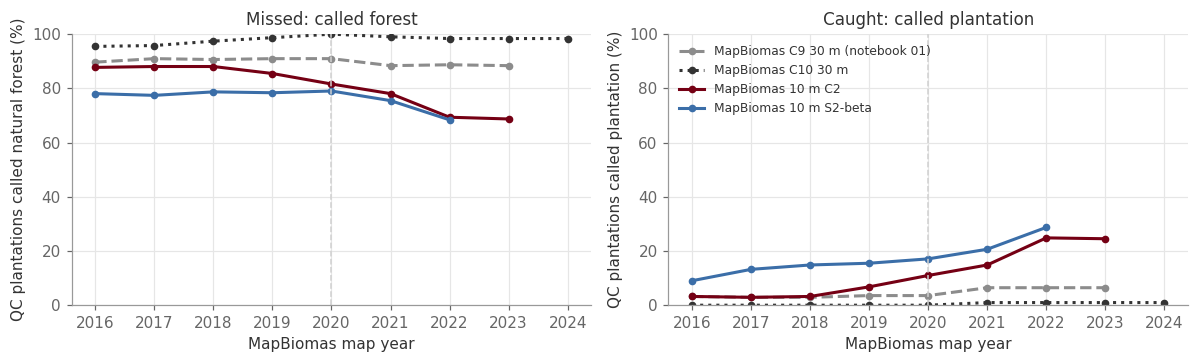

In [4]:
c9 = d[[f"mb_{yr}" for yr in range(2016, 2024)]].rename(columns=lambda c: "mb30c9_" + c[3:])
prod = {"MapBiomas C9 30 m (notebook 01)": ("mb30c9", c9), "MapBiomas C10 30 m": ("mb30c10", d),
        "MapBiomas 10 m C2": ("mb10c2", d), "MapBiomas 10 m S2-beta": ("mb10beta", d)}
rows = []
for name, (pfx, src) in prod.items():
    for yr in range(2016, 2025):
        col = f"{pfx}_{yr}"
        if col not in src: continue
        v = src.loc[d.index, col]
        rows.append(dict(product=name, year=yr,
                         plant_caught_n=int((v[y == 1] == 9).sum()), plant_caught_pct=100 * (v[y == 1] == 9).mean(),
                         plant_called_forest_pct=100 * (v[y == 1] == 3).mean(),
                         forest_called_plant_n=int((v[y == 0] == 9).sum()), forest_called_forest_pct=100 * (v[y == 0] == 3).mean()))
mbp = pd.DataFrame(rows)
display(mbp.pivot(index="product", columns="year", values="plant_caught_n").fillna("–"))
display(mbp[mbp.year.isin([2020, mbp.year.max()]) | ((mbp["product"] == "MapBiomas 10 m S2-beta") & (mbp.year == 2022)) | ((mbp["product"] == "MapBiomas 10 m C2") & (mbp.year == 2023))]
        .set_index(["product", "year"]).round(1))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
sty = {"MapBiomas C9 30 m (notebook 01)": (PAL["grey"], "--"), "MapBiomas C10 30 m": (PAL["ink"], ":"),
       "MapBiomas 10 m C2": (PAL["plantation"], "-"), "MapBiomas 10 m S2-beta": (PAL["forest"], "-")}
for name, (c, ls) in sty.items():
    sub = mbp[mbp["product"] == name]
    axs[0].plot(sub.year, sub.plant_called_forest_pct, color=c, ls=ls, marker="o", ms=4, label=name)
    axs[1].plot(sub.year, sub.plant_caught_pct, color=c, ls=ls, marker="o", ms=4, label=name)
axs[0].set_ylabel("QC plantations called natural forest (%)"); axs[0].set_ylim(0, 100)
axs[1].set_ylabel("QC plantations called plantation (%)"); axs[1].set_ylim(0, 100)
for ax in axs:
    ax.axvline(2020, color=PAL["light"], lw=1, ls="--"); ax.set_xlabel("MapBiomas map year")
axs[0].set_title("Missed: called forest"); axs[1].set_title("Caught: called plantation")
axs[1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); savefig(fig, "02i_mapbiomas_products"); plt.show()

**Reading it.**
- **C10 30 m 2020** calls **all** the QC plantations forest. This fits the alerts being selected
  through Cropin's ensemble, where MapBiomas C10 30 m forest carries weight 3 of 10.
- **C9 30 m 2020** (notebook 01) calls 91% forest. It is an older collection, so it differs from C10.
- **The 10 m products** recognise more plantations every year. By 2022–23, C2 and S2-beta catch
  about a quarter of them. MapBiomas relabels plantations as their stands become visible, but
  only after the EUDR cutoff.

**Reconciling the three headline numbers.** Each is valid for its own question:

| Figure | Product and year | Plantations "missed" |
|---|---|---|
| Notebook 01 | C9 30 m, 2020 (EUDR cutoff) | 91% |
| Julia | 10 m C4, 2025 (latest before the clearings; not in our exports) | 82% |
| Here | 10 m C2 / S2-beta, 2020 | about 80% |
| Here | 10 m C2 / S2-beta, 2022–23 | about 69% |

Because the alerts were selected *through* MapBiomas, these are not fair accuracy estimates for
MapBiomas. The fair question is what new information adds **on top of** Cropin's layer. That is
what the SAG and model sections test.

## (ii) SAG: first quantitative validation on labelled cases

**What SAG measures (plain version).** Take a pixel's blue, green and red brightness. Healthy
light-green leaves have a sharp green peak; dark-green canopies have a flatter, darker spectrum.
SAG is the angle at the green point, so flatter (darker) means a larger angle. Cropin observed
that from October to January plantations look darker green than native forest, by about 10°.
Only dark pixels count: blue, green and red reflectance all ≤ 0.05.

**Measurement limits.**
- Each row is the **polygon mean** SAG of valid pixels (often 1–7 pixels). Cropin works per pixel.
- Each polygon has a median of about 190 valid observations over 2019–2025, and 56 in the Oct–Jan
  windows. Many images are lost to
  clouds or to the dark-pixel rule.
- **Timing.** The QC clearings happened in 2026. The **2025/26 season (Oct 2025–Jan 2026)** could
  already include the clearing, so every result is repeated **without that season**.
- **The 2018/19 season.** The export starts on 2019-01-01, so January 2019 belongs to a partial
  2018/19 season. Cropin's code starts at 2019/20, so we drop it.

### Per-polygon SAG features
- **Cropin's window**, Oct 1–Jan 30 (their date filter excludes Jan 31), seasons 2019/20–2025/26:
  - `sag_octjan`: average over all of them;
  - `sag_octjan_pre`: the same without 2025/26.
- `sag_junaug`: southern **winter** (Jun–Aug), 2019–2025. This is the window Deepak said nobody had tried.
- `sag_all`: all months, 2019 to Jan 2026.
- `sag_winter_minus_summer` = `sag_junaug` − `sag_octjan`: the seasonal swing.

In [5]:
def season_of(dates):
    m, yr = dates.dt.month, dates.dt.year
    in_win = (m >= 10) | ((m == 1) & (dates.dt.day <= 30))          # Oct 1 - Jan 30
    return np.where(in_win, np.where(m >= 10, yr, yr - 1), -1)

sag_day["season"] = season_of(sag_day["date"])
sag["season"] = season_of(sag["date"])
SEASONS = list(range(2019, 2026)); SEASONS_PRE = list(range(2019, 2025))
win = sag_day[sag_day.season.isin(SEASONS)]
feat = pd.DataFrame(index=d.index)
feat["sag_octjan"] = win.groupby("id").sag.mean()
feat["sag_octjan_pre"] = win[win.season.isin(SEASONS_PRE)].groupby("id").sag.mean()
feat["sag_junaug"] = sag_day[sag_day.month.isin([6, 7, 8]) & (sag_day.date.dt.year <= 2025)].groupby("id").sag.mean()
feat["sag_all"] = sag_day.groupby("id").sag.mean()
feat["sag_winter_minus_summer"] = feat["sag_junaug"] - feat["sag_octjan"]
feat["n_dates_octjan"] = win.groupby("id").size()
print("polygons with no valid date in each window:"); print(feat.isna().sum().to_string())
print("valid Oct–Jan dates per polygon (median, min):", int(feat.n_dates_octjan.median()), int(feat.n_dates_octjan.min()))
print(f"dropped partial 2018/19 season rows: {int((sag_day.season == 2018).sum())}")
d = d.join(feat)

polygons with no valid date in each window:
sag_octjan                 0
sag_octjan_pre             0
sag_junaug                 0
sag_all                    0
sag_winter_minus_summer    0
n_dates_octjan             0
valid Oct–Jan dates per polygon (median, min): 56 2
dropped partial 2018/19 season rows: 609


### Plantation vs forest SAG through the year
For each polygon we average SAG by calendar month over all years. We then plot the median
polygon in each group, with the interquartile range.

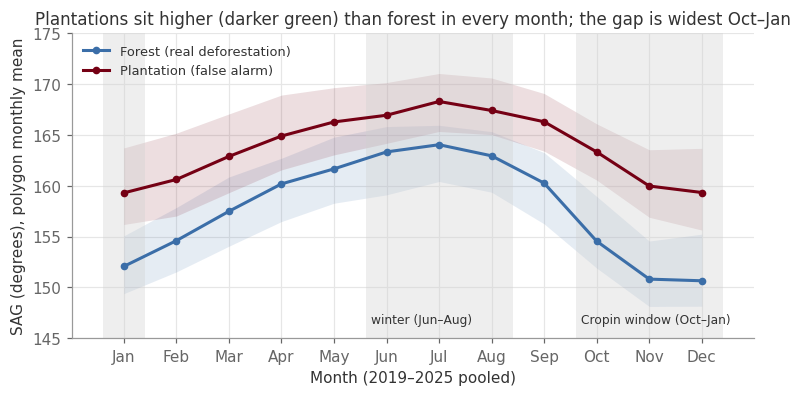

month,1,2,3,4,5,6,7,8,9,10,11,12
plantation − forest median SAG (degrees),7.2,6.0,5.4,4.7,4.6,3.6,4.3,4.5,6.0,8.8,9.2,8.7


In [6]:
mon = sag_day[sag_day.date < "2026-01-01"].groupby(["id", "month"]).sag.mean().unstack()
fig, ax = plt.subplots(figsize=(8, 3.6))
for lab in ["forest", "plantation"]:
    sub = mon.loc[d.index[d.qc_label == lab]]
    ax.plot(range(1, 13), sub.median().values, color=PAL[lab], marker="o", ms=4, label=LABELS[lab])
    ax.fill_between(range(1, 13), sub.quantile(.25).values, sub.quantile(.75).values, color=PAL[lab], alpha=0.13, lw=0)
for (a, b, txt) in [(9.6, 12.4, "Cropin window (Oct–Jan)"), (5.6, 8.4, "winter (Jun–Aug)")]:
    ax.axvspan(a, b, color=PAL["light"], alpha=0.35, lw=0); ax.text(a + 0.1, 146.5, txt, fontsize=8, color=PAL["ink"])
ax.axvspan(0.6, 1.4, color=PAL["light"], alpha=0.35, lw=0)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("SAG (degrees), polygon monthly mean"); ax.set_xlabel("Month (2019–2025 pooled)")
ax.set_ylim(145, 175); ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("Plantations sit higher (darker green) than forest in every month; the gap is widest Oct–Jan")
savefig(fig, "02ii_sag_by_month"); plt.show()
gap = (mon.loc[d.index[d.y == 1]].median() - mon.loc[d.index[d.y == 0]].median()).round(1)
display(gap.rename("plantation − forest median SAG (degrees)").to_frame().T)

In [7]:
TESTS = []
def cont(col, label, src=None):
    src = d if src is None else src
    ok = src[col].notna()
    yy, xx = src.loc[ok, "y"].values, src.loc[ok, col].values
    a, lo, hi = auc_ci(yy, xx, N_BOOT, SEED)
    p = mwu_test(xx[yy == 1], xx[yy == 0])
    TESTS.append(dict(feature=col, description=label, n=int(ok.sum()), median_plantation=np.median(xx[yy == 1]),
                      median_forest=np.median(xx[yy == 0]), AUC=a, ci_low=lo, ci_high=hi,
                      direction=auc_oriented(yy, xx)[1], p_raw=p))

for col, lab in [("sag_octjan", "SAG Oct–Jan, 7 seasons"), ("sag_octjan_pre", "SAG Oct–Jan, excl. 2025/26"),
                 ("sag_junaug", "SAG Jun–Aug (winter)"), ("sag_all", "SAG all months"),
                 ("sag_winter_minus_summer", "SAG winter − summer")]:
    cont(col, lab)
display(pd.DataFrame(TESTS).drop(columns="p_raw").round(3))

,feature,description,n,median_plantation,median_forest,AUC,ci_low,ci_high,direction
0,sag_octjan,"SAG Oct–Jan, 7 seasons",433,160.326,151.880,0.870,0.830,0.907,higher in plantations
1,sag_octjan_pre,"SAG Oct–Jan, excl. 2025/26",433,160.512,151.566,0.871,0.831,0.908,higher in plantations
2,sag_junaug,SAG Jun–Aug (winter),433,167.553,163.513,0.781,0.735,0.828,higher in plantations
3,sag_all,SAG all months,433,163.793,158.166,0.822,0.777,0.866,higher in plantations
4,sag_winter_minus_summer,SAG winter − summer,433,6.946,9.922,0.775,0.723,0.826,lower in plantations


**Reading it.**
- **Strongest single feature so far.** Mean SAG over Cropin's Oct–Jan window separates
  plantations from forest with an **AUC of about 0.87**. Notebook 01's best was Natural Forests
  at 0.72. Dropping the possibly post-clearing 2025/26 season changes almost nothing, so the
  clearing does not drive the signal.
- **Winter is weaker but not useless.** Jun–Aug is the darkest-looking season for both groups,
  but the plantation–forest gap is smaller (AUC ≈ 0.78). Cropin's choice of the summer window is
  confirmed.
- **Seasonal swing.** `sag_winter_minus_summer` captures how much more a canopy changes between
  seasons, and forests swing more. It carries some separate information.

### Rebuilding Cropin's Bayesian posterior
We apply exactly the rule in `cropin_multiyear_SAG_plantation.js`, but to the polygon-mean SAG:
1. For each Oct–Jan season, start at P(plantation) = 0.5.
2. For each observation x (in date order; both tile copies kept, as in Cropin's per-pixel code),
   apply Bayes' rule with plantation ~ N(160°, 9°) and non-plantation ~ N(150°, 9°).
3. Clamp P to 0.1–0.9 after every update. A season with no valid observation stays at 0.5.
4. Average the season posteriors (7 seasons, 2019/20–2025/26) and **flag plantation when the mean ≥ 0.8**.

Cropin also masks with Meta height ≥ 4 m. We report it separately, because it is a forest mask,
not part of SAG.

In [8]:
def season_posterior(x, mu1=160.0, mu0=150.0, sd1=9.0, sd0=9.0):
    p = 0.5
    l1, l0 = norm.pdf(x, mu1, sd1), norm.pdf(x, mu0, sd0)
    for a, b in zip(l1, l0):
        p = a * p / (a * p + b * (1 - p))
        p = min(max(p, 0.1), 0.9)
    return p

obs = (sag[sag.season.isin(SEASONS)].sort_values(["id", "date", "tile"])
       .groupby(["id", "season"]).sag.apply(np.asarray))

def mean_posterior(params_by_season=None, seasons=SEASONS, ids=None):
    ids = d.index if ids is None else ids
    out = pd.Series(0.0, index=ids)
    for s in seasons:
        prm = (160.0, 150.0, 9.0, 9.0) if params_by_season is None else params_by_season[s]
        post = pd.Series(0.5, index=ids)
        for i in ids:
            x = obs.get((i, s))
            if x is not None:
                post[i] = season_posterior(x, *prm)
        out += post
    return out / len(seasons)

d["post_cropin"] = mean_posterior()
d["post_cropin_pre"] = mean_posterior(seasons=SEASONS_PRE)

def flag_summary(score, thr, label, mask=None):
    f = score >= thr if mask is None else (score >= thr) & mask
    return dict(rule=label, plantations_caught_pct=100 * f[y == 1].mean(), plantations_caught_n=int(f[y == 1].sum()),
                forests_flagged_pct=100 * f[y == 0].mean(), forests_flagged_n=int(f[y == 0].sum()))

meta_ok = d["cf_meta_ge4"] >= 0.5
post_tab = pd.DataFrame([
    flag_summary(d.post_cropin, 0.8, "Cropin rule: mean posterior ≥ 0.8 (7 seasons)"),
    flag_summary(d.post_cropin_pre, 0.8, "same, excluding 2025/26 season"),
    flag_summary(d.post_cropin, 0.8, "same, AND Meta ≥ 4 m (as Cropin displays it)", meta_ok),
])
display(post_tab.round(1))
cont("post_cropin", "Cropin posterior (7 seasons)"); cont("post_cropin_pre", "Cropin posterior, excl. 2025/26")
display(pd.DataFrame(TESTS[-2:]).drop(columns="p_raw").round(3))

,rule,plantations_caught_pct,plantations_caught_n,forests_flagged_pct,forests_flagged_n
0,Cropin rule: mean posterior ≥ 0.8 (7 seasons),68.1,211,16.3,20
1,"same, excluding 2025/26 season",68.7,213,15.4,19
2,"same, AND Meta ≥ 4 m (as Cropin displays it)",61.3,190,15.4,19


,feature,description,n,median_plantation,median_forest,AUC,ci_low,ci_high,direction
0,post_cropin,Cropin posterior (7 seasons),433,0.895,0.223,0.869,0.831,0.908,higher in plantations
1,post_cropin_pre,"Cropin posterior, excl. 2025/26",433,0.895,0.233,0.863,0.820,0.904,higher in plantations


**Reading it.**
- **As shipped**, Cropin's rule catches about **two-thirds of plantation false alarms**. But it
  also flags about **16% of real deforestation** (20 of 123 forests) as plantation. For EUDR that
  is far above a "≤ 5% hidden" tolerance.
- **Ranking ability.** The mean posterior ranks cases about as well as raw mean SAG
  (AUC ≈ 0.87). The weakness is the **cut-off**, not the signal.

### Fitting the season parameters to our labels instead of hard-coding them
Cropin's bell curves (160° vs 150°, SD 9°) were set by eye. Here we **estimate a separate mean
and SD for each class and each season** from labelled observations. To keep this honest, the
parameters are estimated **only on training polygons** inside the same spatially blocked
5-fold CV used in notebook 01 (20 KMeans blocks, 20 seeds), then applied to the held-out polygons.

In [9]:
obs_long = sag[sag.season.isin(SEASONS)][["id", "season", "sag"]].merge(d[["y"]], left_on="id", right_index=True)
print("fitted on ALL data, for reference only (not used for scoring):")
display(obs_long.groupby(["season", "y"]).sag.agg(["mean", "std"]).unstack().round(1)
        .rename(columns={0: "forest", 1: "plantation"}))

g_km = spatial_groups(d.reset_index(), k=20, seed=SEED)

def fitted_posterior_cv(seasons, seeds=SEEDS):
    from sklearn.model_selection import StratifiedGroupKFold
    ids = d.index.values; yy = d["y"].values
    rows, scores = [], {}
    for seed in seeds:
        score = pd.Series(np.nan, index=ids)
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(ids, yy, g_km):
            o = obs_long[obs_long.id.isin(ids[tr])]
            st = o.groupby(["season", "y"]).sag.agg(["mean", "std"])
            prm = {s: (st.loc[(s, 1), "mean"], st.loc[(s, 0), "mean"], st.loc[(s, 1), "std"], st.loc[(s, 0), "std"]) for s in seasons}
            score.loc[ids[te]] = mean_posterior(prm, seasons, ids[te]).values
        f = score >= 0.8
        rows.append(dict(seed=seed, auc=roc_auc_score(yy, score), caught=100 * f[yy == 1].mean(), forests_flagged=100 * f[yy == 0].mean()))
        scores[seed] = score
    return pd.DataFrame(rows), scores

fit7, fit7_scores = fitted_posterior_cv(SEASONS)
fitpre, _ = fitted_posterior_cv(SEASONS_PRE)
fit_tab = pd.DataFrame({
    "Cropin hard-coded (no fitting)": dict(AUC=roc_auc_score(y, d.post_cropin), caught_pct=post_tab.iloc[0].plantations_caught_pct, forests_flagged_pct=post_tab.iloc[0].forests_flagged_pct),
    "Fitted per season, spatial CV (7 seasons)": dict(AUC=fit7.auc.mean(), caught_pct=fit7.caught.mean(), forests_flagged_pct=fit7.forests_flagged.mean()),
    "Fitted per season, spatial CV (excl. 2025/26)": dict(AUC=fitpre.auc.mean(), caught_pct=fitpre.caught.mean(), forests_flagged_pct=fitpre.forests_flagged.mean()),
}).T
display(fit_tab.round(3))
print("fitted, 7 seasons, spread over seeds: caught ± %.1f, forests flagged ± %.1f" % (fit7.caught.std(), fit7.forests_flagged.std()))
d["post_fitted_cv"] = fit7_scores[0]

fitted on ALL data, for reference only (not used for scoring):


mean               std           
y      forest plantation forest plantation
season                                    
2019    152.5      159.3    6.3        5.6
2020    153.5      161.1    5.8        5.7
2021    152.2      160.6    5.9        5.6
2022    153.2      161.3    6.0        5.9
2023    154.4      161.9    5.8        5.6
2024    153.1      160.9    5.8        5.7
2025    153.3      160.5    6.2        6.1

,AUC,caught_pct,forests_flagged_pct
Cropin hard-coded (no fitting),0.869,68.065,16.260
"Fitted per season, spatial CV (7 seasons)",0.852,54.968,13.089
"Fitted per season, spatial CV (excl. 2025/26)",0.851,55.387,14.350


fitted, 7 seasons, spread over seeds: caught ± 1.5, forests flagged ± 0.3


**Reading it.**
- **The fitted centres are close to Cropin's.** Forest sits at about 153° and plantation at
  about 161°. Uddesh's 10° gap is really about 8° on polygon means.
- **That moves the tipping point.** With equal SDs, an image counts as evidence for plantation
  when SAG is above the midpoint of the two centres. That midpoint moves from Cropin's **155°**
  to about **157°**. The fitted SDs are also narrower (≈ 6° vs 9°), so each image moves the
  posterior further.
- **Net effect at the ≥ 0.8 cut-off: fewer flags of both kinds.** About 55% of plantations are
  caught and about 13% of forests flagged, against 68% and 16% hard-coded. The AUC is slightly
  *lower* (≈ 0.85 vs 0.87).
- **What this means.** Better bell curves do not fix SAG's problem. The overlap is in the data.
  What matters is the operating threshold, and adding information that separates the forests
  SAG confuses.

### The "dark native pine" problem: which forests does SAG call plantation?
Uddesh warned that a dark native pine (likely *Araucaria*) fools SAG. We cannot see species
here. But we can ask whether the **forests that Cropin's rule wrongly flags** differ in
**land history** from the **plantations it correctly flags**. If they do, combining SAG with
history could remove those errors.

In [10]:
flag = d.post_cropin >= 0.8
ff, fp = d[flag & (y == 0)], d[flag & (y == 1)]
print(f"flagged by Cropin's rule: {len(fp)} plantations (correct), {len(ff)} forests (wrong)")
hist_rows = []
for c in ["forest_every_year", "after2000", "farm_any"]:
    r = fisher_test(ff[c], fp[c]); hist_rows.append(dict(feature=c, wrongly_flagged_forests=f"{r['pct_a']:.0f}% ({r['n_a']}/{r['N_a']})",
                                                       correctly_flagged_plantations=f"{r['pct_b']:.0f}% ({r['n_b']}/{r['N_b']})",
                                                       odds_ratio=round(r["odds_ratio"], 2), p_fisher=r["p"]))
    TESTS.append(dict(feature=c, description=f"{c}: SAG-flagged forests vs SAG-flagged plantations", n=len(ff) + len(fp),
                      median_plantation=r["pct_b"], median_forest=r["pct_a"], AUC=np.nan, ci_low=np.nan, ci_high=np.nan,
                      direction="share (%)", p_raw=r["p"]))
for c in ["n_yrs_forest", "n_class_changes", "nf_prob", "height_mean"]:
    sub = pd.concat([ff, fp]); yy = sub.y.values; a, lo, hi = auc_ci(yy, sub[c].values, N_BOOT, SEED)
    p = mwu_test(fp[c], ff[c])
    hist_rows.append(dict(feature=c, wrongly_flagged_forests=f"median {ff[c].median():.2f}", correctly_flagged_plantations=f"median {fp[c].median():.2f}",
                          odds_ratio=np.nan, p_fisher=np.nan, AUC_within_flagged=f"{a:.2f} ({lo:.2f}-{hi:.2f})", p_mwu=p))
    TESTS.append(dict(feature=c, description=f"{c}: SAG-flagged plantations vs SAG-flagged forests", n=len(ff) + len(fp),
                      median_plantation=fp[c].median(), median_forest=ff[c].median(), AUC=a, ci_low=lo, ci_high=hi,
                      direction=auc_oriented(yy, sub[c].values)[1], p_raw=p))
display(pd.DataFrame(hist_rows))

flagged by Cropin's rule: 211 plantations (correct), 20 forests (wrong)


,feature,wrongly_flagged_forests,correctly_flagged_plantations,odds_ratio,p_fisher,AUC_within_flagged,p_mwu
0,forest_every_year,65% (13/20),47% (100/211),2.06,0.163,NaN,NaN
1,after2000,25% (5/20),41% (86/211),0.48,0.232,NaN,NaN
2,farm_any,35% (7/20),48% (102/211),0.58,0.349,NaN,NaN
3,n_yrs_forest,median 39.00,median 36.00,NaN,NaN,0.58 (0.44-0.70),0.224
4,n_class_changes,median 0.00,median 1.00,NaN,NaN,0.63 (0.52-0.73),0.046
5,nf_prob,median 0.63,median 0.44,NaN,NaN,0.62 (0.48-0.75),0.074
6,height_mean,median 24.21,median 25.04,NaN,NaN,0.54 (0.42-0.65),0.577


**Reading it.**
- **Land history points the right way.** The wrongly flagged forests are more often "forest
  every year" and have more years as forest than the plantations SAG correctly flags.
- **But there are only 20 such forests.** The differences are modest and do not survive the
  multiple-testing correction below.
- **Class changes and Natural Forests** show the clearest differences within this flagged group
  (AUC ≈ 0.62–0.63), but are not significant after correction.
- **Verdict.** Combining is worth testing (section iv), but land history alone is not a clean fix
  for SAG's confusion.

### All SAG-section tests with the Holm correction

In [11]:
tests = pd.DataFrame(TESTS)
tests["p_holm"] = holm(tests["p_raw"])
show = tests[["description", "n", "AUC", "ci_low", "ci_high", "direction", "p_raw", "p_holm"]].copy()
show["p_raw"] = show.p_raw.map("{:.1e}".format); show["p_holm"] = show.p_holm.map("{:.1e}".format)
display(show.round(3))

,description,n,AUC,ci_low,ci_high,direction,p_raw,p_holm
0,"SAG Oct–Jan, 7 seasons",433,0.870,0.830,0.907,higher in plantations,3.4e-33,4.0e-32
1,"SAG Oct–Jan, excl. 2025/26",433,0.871,0.831,0.908,higher in plantations,2.5e-33,3.2e-32
2,SAG Jun–Aug (winter),433,0.781,0.735,0.828,higher in plantations,6.9e-20,6.2e-19
3,SAG all months,433,0.822,0.777,0.866,higher in plantations,1.6e-25,1.6e-24
4,SAG winter − summer,433,0.775,0.723,0.826,lower in plantations,3.8e-19,3.0e-18
5,Cropin posterior (7 seasons),433,0.869,0.831,0.908,higher in plantations,4.7e-34,6.6e-33
6,"Cropin posterior, excl. 2025/26",433,0.863,0.820,0.904,higher in plantations,3.7e-33,4.1e-32
7,forest_every_year: SAG-flagged forests vs SAG-...,231,NaN,NaN,NaN,share (%),1.6e-01,8.1e-01
8,after2000: SAG-flagged forests vs SAG-flagged ...,231,NaN,NaN,NaN,share (%),2.3e-01,9.0e-01
9,farm_any: SAG-flagged forests vs SAG-flagged p...,231,NaN,NaN,NaN,share (%),3.5e-01,9.0e-01


## (iii) Height variability *inside* the stand (Meta 1 m) vs the old 30 m circle

Notebook 01, finding 3, found plantations *more* uneven in height, the opposite of the "planted
together, so uniform" hypothesis. We suspected an artefact: the ETH measure is a 30 m-radius
circle at 10 m, which mostly captures the surroundings.

Meta's 1 m canopy height map lets us measure spread **inside the polygon itself**:
- `meta_sd`: standard deviation of 1 m pixels;
- `meta_range`: p90 − p10;
- `meta_mean`: average height.

If the artefact explanation is right, plantations should look *as smooth or smoother* inside
than forests.

**Limitations of Meta's map.**
- Its heights come from imagery of **varying dates** (roughly 2009–2020 in this region).
- It is known to **under-estimate tall canopies**.
- Here its median is about 8 m against ETH's about 23 m, and the two correlate only moderately
  (Spearman 0.39).
- Its SD grows with polygon size (more 1 m pixels, more chance of edges). Plantation and forest
  polygons have the same size distribution (notebook 01), so size does not create the class
  difference, but it adds noise.
- A polygon partly cut or replanted at Meta's image date would look uneven for reasons unrelated
  to species.

,feature,median_plantation,median_forest,AUC,ci,direction,p_mwu,p_holm (within this table)
0,Meta 1 m height SD inside polygon (m),2.080,1.463,0.640,0.58-0.70,higher in plantations,0.000,0.000
1,Meta 1 m p90 − p10 inside polygon (m),5.000,4.000,0.634,0.58-0.69,higher in plantations,0.000,0.000
2,Meta 1 m mean height inside polygon (m),8.626,7.841,0.545,0.48-0.60,higher in plantations,0.145,0.145
3,"ETH height SD, 30 m circle (m) [notebook 01]",1.479,1.118,0.663,0.61-0.72,higher in plantations,0.000,0.000
4,ETH mean height inside polygon (m) [notebook 01],24.190,21.174,0.706,0.65-0.76,higher in plantations,0.000,0.000


correlations:


,meta_mean,height_mean,meta_sd,height_sd_30m,meta_npix
meta_mean,1.00,0.39,0.06,-0.05,0.11
height_mean,0.39,1.00,0.12,0.15,-0.01
meta_sd,0.06,0.12,1.00,0.08,0.43
height_sd_30m,-0.05,0.15,0.08,1.00,-0.13
meta_npix,0.11,-0.01,0.43,-0.13,1.00


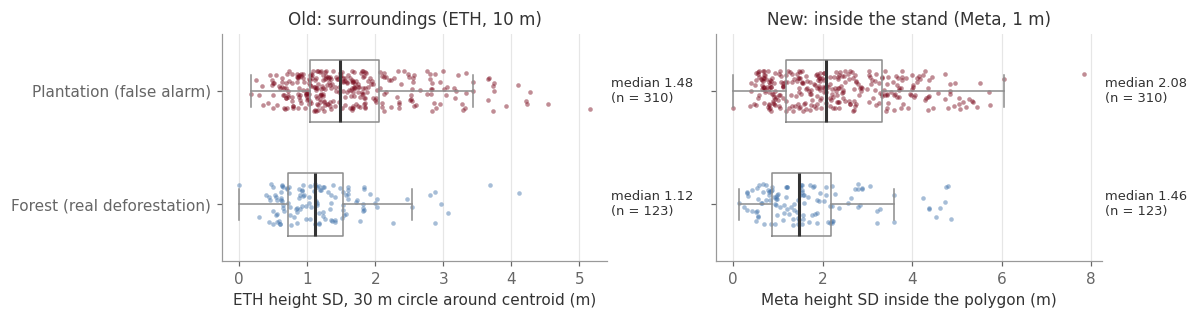

In [12]:
meta_tests = []
for col, lab in [("meta_sd", "Meta 1 m height SD inside polygon (m)"), ("meta_range", "Meta 1 m p90 − p10 inside polygon (m)"),
                 ("meta_mean", "Meta 1 m mean height inside polygon (m)"), ("height_sd_30m", "ETH height SD, 30 m circle (m) [notebook 01]"),
                 ("height_mean", "ETH mean height inside polygon (m) [notebook 01]")]:
    a, lo, hi = auc_ci(y.values, d[col].values, N_BOOT, SEED)
    meta_tests.append(dict(feature=lab, median_plantation=d.loc[y == 1, col].median(), median_forest=d.loc[y == 0, col].median(),
                           AUC=a, ci=f"{lo:.2f}-{hi:.2f}", direction=auc_oriented(y.values, d[col].values)[1],
                           p_mwu=mwu_test(d.loc[y == 1, col], d.loc[y == 0, col])))
mt = pd.DataFrame(meta_tests); mt["p_holm (within this table)"] = holm(mt.p_mwu)
display(mt.round(3))
print("correlations:"); display(d[["meta_mean", "height_mean", "meta_sd", "height_sd_30m", "meta_npix"]].corr(method="spearman").round(2))

fig, axs = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
dist_plot(axs[0], d, "height_sd_30m", "ETH height SD, 30 m circle around centroid (m)"); axs[0].set_title("Old: surroundings (ETH, 10 m)")
dist_plot(axs[1], d, "meta_sd", "Meta height SD inside the polygon (m)"); axs[1].set_title("New: inside the stand (Meta, 1 m)")
plt.tight_layout(); savefig(fig, "02iii_height_variability"); plt.show()

**Reading it.**
- **The artefact explanation is not supported.** Measured **inside the polygon at 1 m**,
  plantations are still *more* variable in height than forests (AUC ≈ 0.64, similar to the old
  circle measure). So "plantations are uneven" is not only about their surroundings.
- **Caution.** Meta's low absolute heights and mixed image dates mean part of this variability
  could reflect stands that were young, thinned or partly harvested when Meta's imagery was taken.
  Rotation forestry would produce exactly that. Uddesh's "smooth inside" impression comes from
  current high-resolution imagery of mature stands.
- **Next step.** Check a few polygons visually against Meta's image dates.
- **Meta mean height** separates the groups only weakly (AUC ≈ 0.55), much less than ETH. It is
  not a substitute for ETH height.

## (iv) Does SAG (and Meta) improve the combined model?

**Candidates.** We add to the notebook-01 five-feature model:
- **the best SAG feature, `sag_octjan`**, plus the robustness version without 2025/26;
- **`meta_sd`**, the Meta feature with the strongest single-feature signal.

The SAG feature was chosen as "best" on these same data. Its gain is therefore slightly optimistic.

**Evaluation.** Exactly as in notebook 01:
- logistic regression on standardized features;
- **spatially blocked 5-fold CV** (the same 20 KMeans blocks), 20 seeds;
- the **nested ≤ 5%-forest threshold** chosen inside each training fold.

**Comparisons.**
- **Cropin's posterior alone.** It is used as a single score; the logistic regression on one
  feature only rescales it, so its ranking is unchanged. Its nested threshold is learned the same way.
- **Cropin's fixed ≥ 0.8 rule.**
- **Notebook 01's model.**

In [13]:
F7 = ["nf_prob", "height_mean", "height_sd_30m", "n_class_changes", "n_yrs_forest"]
models = {
    "Notebook 01: five features": F7,
    "Cropin SAG posterior alone": ["post_cropin"],
    "SAG Oct–Jan alone": ["sag_octjan"],
    "Five + SAG Oct–Jan": F7 + ["sag_octjan"],
    "Five + SAG Oct–Jan + Meta SD": F7 + ["sag_octjan", "meta_sd"],
    "Five + SAG Oct–Jan (excl. 2025/26) + Meta SD": F7 + ["sag_octjan_pre", "meta_sd"],
    "SAG Oct–Jan + NF + land history": ["sag_octjan", "nf_prob", "n_class_changes", "n_yrs_forest"],
}
assert d[sorted({c for v in models.values() for c in v})].notna().all().all(), "missing values in model features"
res = {}
for name, cols in models.items():
    r, oof = cv_evaluate(d[cols].values, y.values, g_km, "group", SEEDS)
    res[name] = (r, oof)
tab = pd.DataFrame({name: {
    "spatial CV AUC": f"{r.auc.mean():.3f} ± {r.auc.std():.3f}",
    "removed at ≤5% (nested) %": f"{r.nest_caught.mean():.1f} ± {r.nest_caught.std():.1f}",
    "forest actually hidden %": f"{r.nest_hidden.mean():.1f} ± {r.nest_hidden.std():.1f}"} for name, (r, _) in res.items()}).T
fixed = flag_summary(d.post_cropin, 0.8, "")
tab.loc["Cropin fixed rule (posterior ≥ 0.8), no CV needed"] = ["%.3f (ranking AUC)" % roc_auc_score(y, d.post_cropin),
                                                               f"{fixed['plantations_caught_pct']:.1f}", f"{fixed['forests_flagged_pct']:.1f}"]
display(tab)
for name in ["Notebook 01: five features", "Five + SAG Oct–Jan + Meta SD", "Cropin SAG posterior alone"]:
    a, lo, hi = auc_ci(y.values, res[name][1][0], N_BOOT, SEED)
    print(f"{name:32s} seed-0 AUC {a:.3f} (bootstrap 95% CI {lo:.3f}-{hi:.3f})")

,spatial CV AUC,removed at ≤5% (nested) %,forest actually hidden %
Notebook 01: five features,0.811 ± 0.005,30.0 ± 2.4,5.3 ± 1.1
Cropin SAG posterior alone,0.843 ± 0.009,5.2 ± 7.6,1.1 ± 1.6
SAG Oct–Jan alone,0.857 ± 0.008,34.4 ± 2.1,5.1 ± 0.8
Five + SAG Oct–Jan,0.885 ± 0.004,49.1 ± 2.9,5.0 ± 1.3
Five + SAG Oct–Jan + Meta SD,0.888 ± 0.005,48.5 ± 3.5,4.7 ± 1.3
Five + SAG Oct–Jan (excl. 2025/26) + Meta SD,0.888 ± 0.005,49.0 ± 3.4,4.3 ± 1.1
SAG Oct–Jan + NF + land history,0.884 ± 0.005,44.8 ± 2.6,4.2 ± 1.6
"Cropin fixed rule (posterior ≥ 0.8), no CV needed",0.869 (ranking AUC),68.1,16.3


Notebook 01: five features       seed-0 AUC 0.808 (bootstrap 95% CI 0.762-0.852)


Five + SAG Oct–Jan + Meta SD     seed-0 AUC 0.885 (bootstrap 95% CI 0.848-0.921)


Cropin SAG posterior alone       seed-0 AUC 0.842 (bootstrap 95% CI 0.793-0.890)


precision  recall  n_true
Five + SAG Oct–Jan + Meta SD (nested ≤5%, spati... plantation (flagged)      0.963   0.485     310
                                                   forest (kept)             0.423   0.953     123
Cropin fixed rule (posterior ≥ 0.8)                plantation (flagged)      0.913   0.681     310
                                                   forest (kept)             0.510   0.837     123

,coef,ci_low,ci_high
nf_prob,-0.53,-0.89,-0.24
height_mean,0.33,0.06,0.65
height_sd_30m,0.29,0.01,0.63
n_class_changes,1.00,0.35,1.66
n_yrs_forest,0.26,-0.24,0.68
sag_octjan,1.55,1.23,2.03
meta_sd,0.29,-0.03,0.67


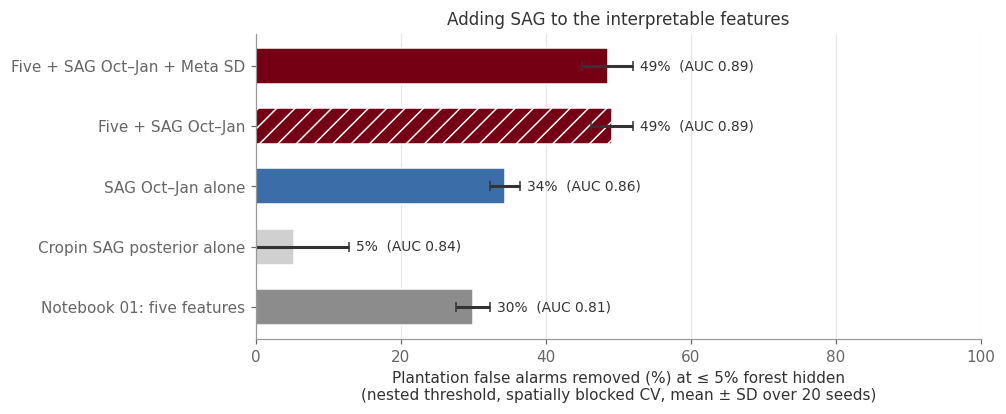

In [14]:
best = "Five + SAG Oct–Jan + Meta SD"
r_b = res[best][0]
display(pd.concat({f"{best} (nested ≤5%, spatial CV, pooled over seeds)": per_class_metrics(r_b.TP.sum(), r_b.FP.sum(), r_b.FN.sum(), r_b.TN.sum()).assign(n_true=lambda t: t.n_true // len(SEEDS)),
                   "Cropin fixed rule (posterior ≥ 0.8)": per_class_metrics(fixed["plantations_caught_n"], fixed["forests_flagged_n"],
                                                                             310 - fixed["plantations_caught_n"], 123 - fixed["forests_flagged_n"])}).round(3))
coefs = bootstrap_coefs(d[models[best]].values, y.values, models[best], N_BOOT, SEED)
display(coefs.round(2))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
show_m = ["Notebook 01: five features", "Cropin SAG posterior alone", "SAG Oct–Jan alone", "Five + SAG Oct–Jan", "Five + SAG Oct–Jan + Meta SD"]
colors = [PAL["grey"], PAL["light"], PAL["forest"], PAL["plantation"], PAL["plantation"]]
for i, (m, c) in enumerate(zip(show_m, colors)):
    r = res[m][0]
    ax.barh(i, r.nest_caught.mean(), xerr=r.nest_caught.std(), color=c, height=0.6, ecolor=PAL["ink"], capsize=3,
            hatch="//" if m == "Five + SAG Oct–Jan" else None, edgecolor="white")
    ax.text(r.nest_caught.mean() + r.nest_caught.std() + 1, i, f"{r.nest_caught.mean():.0f}%  (AUC {r.auc.mean():.2f})", va="center", fontsize=9)
ax.set_yticks(range(len(show_m)), show_m); ax.set_xlim(0, 100)
ax.set_xlabel("Plantation false alarms removed (%) at ≤ 5% forest hidden\n(nested threshold, spatially blocked CV, mean ± SD over 20 seeds)")
ax.set_title("Adding SAG to the interpretable features"); ax.grid(axis="y", visible=False)
savefig(fig, "02iv_model_comparison"); plt.show()

**Reading it.**
- **SAG is the single most valuable addition.** Adding Oct–Jan SAG to the notebook-01 features
  raises the spatially blocked AUC from **0.81 to about 0.89**. At the cautious ≤ 5%-forest
  operating point, plantation false alarms removed go from **about 30% to about 49%**. SAG has by
  far the largest coefficient.
- **The combination beats SAG alone** (about 34% removed). Height, Natural Forests and land
  history add information that SAG lacks.
- **Cropin's posterior alone does poorly at ≤ 5%** (about 5% removed, very unstable). Clamping each
  season at 0.9 makes many polygons **tie at the maximum score**: 134 sit at exactly 0.9, including 6 forests.
  A training fold holds about 98 forests, so "≤ 5%" allows only about 4. A
  cut-off that hides ≤ 5% of forest must sit above that tie and so flags almost nothing. Raw mean
  SAG has no such ceiling and works much better.
- **Meta SD adds nothing measurable** on top of SAG (its coefficient's CI crosses zero).
- **Dropping the 2025/26 season** gives nearly identical results, so this is not leakage from the
  clearing itself.
- **Against Cropin's fixed ≥ 0.8 rule.** That rule catches more plantations but hides about 16%
  of real deforestation. Our threshold is tuned for ≤ 5%, so the two are different trade-offs of
  similar raw signal.

**Caveats.**
- These are still 433 biased, partly repeated QC cases, and features were chosen on them.
- SAG relies on dark pixels and cloud-free Oct–Jan images, so coverage may be worse elsewhere.
- **Next steps.** Validate SAG + features on the 2,290 MapBiomas reference points and on a fresh
  week of Cropin alerts. Map a small region of interest to look for the dark-native-pine pattern.

## Summary

| Question | Answer (exploratory, QC set) |
|---|---|
| Does the QC set match Cropin's layer "by construction"? | **Only partly.** All pass the ensemble score / C10 30 m forest, but only about 55% of plantations pass the final flag at polygon level. Ask Cropin which version produced the alerts. |
| How much does MapBiomas miss? | C10 30 m 2020: 100%. C9 30 m 2020: 91%. 10 m C2 / beta 2020: about 80%. 10 m 2022–23: about 69%. Julia's 10 m C4 2025: 82%. Different products and years, all valid for their question. |
| Does SAG work on labelled cases? | **Yes, it is the strongest single feature** (Oct–Jan mean AUC ≈ 0.87). Summer beats winter (≈ 0.78). It is robust to dropping 2025/26. |
| Cropin's posterior rule as shipped | Catches about two-thirds of plantations but flags about 16% of real forest. The weakness is the threshold and the 0.9 clamp, not the ranking. Fitting the bell curves to our labels gives 55% caught and 13% forest flagged, which doesn't fix it. |
| Dark native pine (forests SAG flags) | Land history leans the right way but does not clearly separate them (20 cases). |
| Uneven height an artefact of the 30 m circle? | **No.** Plantations are more variable inside the polygon at 1 m too, with the Meta date caveat. |
| SAG in the combined model | Biggest improvement so far: spatial CV AUC 0.81 → 0.89, and plantation false alarms removed at ≤ 5% forest hidden go from about 30% to about 49%. Meta SD adds nothing. |